# Modelling, part 2: baseline and metrics

**Goal of this notebook.** Before training any "real" model, establish the **bar to beat**: what a model with no intelligence at all would score under the exact validation scheme we will use later. Along the way you learn to read R², RMSE and MAE in cross-validation.

**Why a baseline?** A model with R² = 0.60 sounds good, but it is only good if a trivial rule cannot do almost as well. The baseline turns a number into a verdict.

**Contents**
0. Setup
1. Loading the data
2. The three metrics, explained
3. Baseline A: always predict the training mean
4. Checking one fold by hand
5. Evaluating with country-grouped cross-validation
6. Baseline B: the mean of each year (a tougher benchmark)
7. Leave-one-country-out
8. Results table and chart
9. How to read these numbers
10. Checklist before moving on

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = next((p for p in [Path(".."), Path(".")] if (p / "data" / "processed").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed: open the project from its root folder.")

FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Loading the data

We load the file saved by the previous notebook. For the baselines we do not need the explanatory variables at all: only the target, the year and the country (the group).

In [2]:
df = pd.read_csv(ROOT / "data" / "processed" / "model_data.csv")
y = df["business_index"].to_numpy()
X = df[["year"]]                 # a baseline ignores the features; "year" is only used by baseline B
groups = df["country"].to_numpy()

print("Rows:", len(df), "| Countries:", df["country"].nunique())
print("Target mean: %.3f | std: %.3f" % (y.mean(), y.std()))

Rows: 81 | Countries: 27
Target mean: -0.000 | std: 0.846


## 2. The three metrics, explained

For each observation *i*, the **error** is `y_i − ŷ_i` (actual minus predicted).

| Metric | Formula | Unit | Intuition |
|---|---|---|---|
| **MAE** | mean of `|error|` | same as the target | the *typical* miss, every error counts equally |
| **RMSE** | √ mean of `error²` | same as the target | like MAE but big misses weigh more; always ≥ MAE |
| **R²** | `1 − Σerror² / Σ(y − ȳ)²` | none | share of the variation in `y` that the model explains **compared with always predicting the mean of the data being evaluated** |

Key facts to remember:

- R² = 1 is perfect; R² = 0 means "no better than predicting the mean"; **R² < 0 means worse than predicting the mean**.
- The target is a mean of z-scores, so its values are in "standard-deviation-like" units: an RMSE of 0.5 means typical misses of about half a standard deviation of a single indicator.
- In cross-validation the model is scored on data it has never seen, so R² can be negative even for sensible models. That is normal and informative, not a bug.

## 3. Baseline A: always predict the training mean

The simplest possible model: ignore every variable and, for any country, predict **the mean of the target in the training data**.

`DummyRegressor(strategy="mean")` does exactly this. Note that it uses the *training* mean, not the test mean: this is what makes the baseline honest.

Why would its R² be close to zero but slightly negative? R² compares the model with the mean *of the test data*. The training mean is never exactly equal to it, so the baseline is always a little worse than that reference.

In [3]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X, y)
print("A single fit on all data predicts the same value for everybody: %.3f" % baseline.predict(X)[0])

A single fit on all data predicts the same value for everybody: -0.000


## 4. Checking one fold by hand

Before trusting a library, reproduce one calculation with plain NumPy. We use `GroupKFold` with 5 folds: every fold holds out about 5–6 **whole countries** (all their years together), trains on the rest and predicts the held-out countries.

In [4]:
gkf = GroupKFold(n_splits=5)
train_idx, test_idx = next(gkf.split(X, y, groups))

print("Fold 1 -> train rows: %d | test rows: %d" % (len(train_idx), len(test_idx)))
print("Test countries:", sorted(set(groups[test_idx])))
assert set(groups[train_idx]).isdisjoint(groups[test_idx]), "A country appears in both train and test!"

# by hand
train_mean = y[train_idx].mean()
y_test = y[test_idx]
pred = np.full(len(test_idx), train_mean)
err = y_test - pred

mae_hand = np.abs(err).mean()
rmse_hand = np.sqrt((err ** 2).mean())
r2_hand = 1 - (err ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()

# with scikit-learn
m = clone(baseline).fit(X.iloc[train_idx], y[train_idx])
p = m.predict(X.iloc[test_idx])

print()
print("            by hand   scikit-learn")
print("MAE     %9.4f   %9.4f" % (mae_hand, mean_absolute_error(y_test, p)))
print("RMSE    %9.4f   %9.4f" % (rmse_hand, np.sqrt(mean_squared_error(y_test, p))))
print("R2      %9.4f   %9.4f" % (r2_hand, r2_score(y_test, p)))

assert np.isclose(r2_hand, r2_score(y_test, p)) and np.isclose(rmse_hand, np.sqrt(mean_squared_error(y_test, p)))

Fold 1 -> train rows: 63 | test rows: 18
Test countries: ['BE', 'DK', 'FR', 'LT', 'PL', 'SK']

            by hand   scikit-learn
MAE        0.7738      0.7738
RMSE       0.9525      0.9525
R2        -0.0666     -0.0666


The two columns match, so we know exactly what the library does.

## 5. Evaluating with country-grouped cross-validation

Now we repeat the procedure for every fold. The helper below returns two views of the results:

- **per-fold metrics**: one row per fold. Useful to see how unstable the estimate is. Each fold has only about 16 observations, so R² per fold is noisy;
- **pooled out-of-fold (OOF) metrics**: every observation is predicted exactly once, by a model that never saw its country; metrics are computed on all 81 predictions together. This is the number we will report in the README.

In [5]:
def cv_evaluate(model, X, y, groups, splitter):
    """Cross-validate by groups. Returns (per-fold table, pooled metrics dict, OOF predictions)."""
    oof = np.full(len(y), np.nan)
    rows = []
    for k, (tr, te) in enumerate(splitter.split(X, y, groups), start=1):
        m = clone(model).fit(X.iloc[tr], y[tr])
        pred = m.predict(X.iloc[te])
        oof[te] = pred
        rows.append({
            "fold": k, "n_test": len(te),
            "R2": r2_score(y[te], pred),
            "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
            "MAE": mean_absolute_error(y[te], pred),
        })
    assert not np.isnan(oof).any(), "Some observations were never predicted"
    pooled = {
        "R2": r2_score(y, oof),
        "RMSE": np.sqrt(mean_squared_error(y, oof)),
        "MAE": mean_absolute_error(y, oof),
    }
    return pd.DataFrame(rows).set_index("fold"), pooled, oof

In [6]:
folds_A, pooled_A, oof_A = cv_evaluate(DummyRegressor(strategy="mean"), X, y, groups, GroupKFold(n_splits=5))

display(folds_A)
print("Per-fold average : R2 %.3f | RMSE %.3f | MAE %.3f" % tuple(folds_A[["R2", "RMSE", "MAE"]].mean()))
print("Pooled OOF       : R2 %.3f | RMSE %.3f | MAE %.3f" % (pooled_A["R2"], pooled_A["RMSE"], pooled_A["MAE"]))

,n_test,R2,RMSE,MAE
fold,,,,
1,18,-0.067,0.952,0.774
2,18,-0.780,0.932,0.682
3,15,-0.506,0.699,0.584
4,15,-2.261,1.060,0.893
5,15,-0.530,0.853,0.695


Per-fold average : R2 -0.829 | RMSE 0.899 | MAE 0.725
Pooled OOF       : R2 -0.158 | RMSE 0.910 | MAE 0.726


**What to notice.**

- Per-fold R² values are all negative and vary a lot from fold to fold: with ~16 observations, the mean of the held-out countries differs from the training mean, and R² punishes that gap heavily. A single "unlucky" fold (e.g. one with several very high or very low countries) can reach R² far below -1.
- The pooled R² is also negative but much closer to zero than the per-fold values. This is the textbook behaviour of the mean baseline: it cannot be positive when evaluated on unseen data.
- The RMSE of this baseline is roughly the standard deviation of the target: predicting a constant can never do better than that.

**Per-fold vs pooled.** Per-fold R² uses a different reference mean in every fold, so averaging it is awkward. We will report the **pooled** metrics as the main numbers and show the per-fold spread as a measure of uncertainty.

## 6. Baseline B: the mean of each year (a tougher benchmark)

In the EDA we saw that digitalisation rose over time in *all* countries. A model that merely knows "2025 is higher than 2021" already captures part of the variation without understanding anything about countries.

Baseline B predicts, for each observation, **the training mean of the target for that observation's year**. If our later models do not beat this benchmark, their apparent skill is just the common time trend.

In [7]:
class YearMeanRegressor(BaseEstimator, RegressorMixin):
    """Predict the training mean of the target for the observation's year (global mean if the year is unseen)."""

    def fit(self, X, y):
        self.global_mean_ = float(np.mean(y))
        self.year_means_ = pd.Series(np.asarray(y)).groupby(X["year"].to_numpy()).mean()
        return self

    def predict(self, X):
        return X["year"].map(self.year_means_).fillna(self.global_mean_).to_numpy()


folds_B, pooled_B, oof_B = cv_evaluate(YearMeanRegressor(), X, y, groups, GroupKFold(n_splits=5))

display(folds_B)
print("Pooled OOF       : R2 %.3f | RMSE %.3f | MAE %.3f" % (pooled_B["R2"], pooled_B["RMSE"], pooled_B["MAE"]))
print()
print("Mean of the target by year (whole sample):")
print(df.groupby("year")["business_index"].mean().round(3).to_string())

,n_test,R2,RMSE,MAE
fold,,,,
1,18,0.141,0.855,0.667
2,18,-0.454,0.842,0.640
3,15,-0.080,0.592,0.469
4,15,-1.956,1.009,0.882
5,15,-0.304,0.788,0.559


Pooled OOF       : R2 0.037 | RMSE 0.830 | MAE 0.644

Mean of the target by year (whole sample):
year
2021   -0.374
2023   -0.140
2025    0.514


Baseline B should score better than A on every pooled metric. That improvement is "free": it comes only from the common upward trend. Note how small the gain is under `GroupKFold(5)` compared with leave-one-country-out: with folds of 5–6 countries, the yearly means estimated on the training countries are themselves noisy. **Baseline B is the number the real models must beat.**

## 7. Leave-one-country-out

`LeaveOneGroupOut` is the extreme version: 27 folds, each holding out one country (its 3 observations). It uses as much training data as possible and is the most faithful simulation of "predict a country the model has never seen". We compute only pooled metrics here, because a single country has just 3 points and a per-fold R² would be meaningless.

In [8]:
logo = LeaveOneGroupOut()
assert logo.get_n_splits(X, y, groups) == 27

_, pooled_A_logo, oof_A_logo = cv_evaluate(DummyRegressor(strategy="mean"), X, y, groups, logo)
_, pooled_B_logo, oof_B_logo = cv_evaluate(YearMeanRegressor(), X, y, groups, logo)

print("LOGO, baseline A: R2 %.3f | RMSE %.3f | MAE %.3f" % tuple(pooled_A_logo.values()))
print("LOGO, baseline B: R2 %.3f | RMSE %.3f | MAE %.3f" % tuple(pooled_B_logo.values()))

LOGO, baseline A: R2 -0.060 | RMSE 0.871 | MAE 0.695
LOGO, baseline B: R2 0.135 | RMSE 0.787 | MAE 0.598


## 8. Results table and chart

We collect the pooled metrics in one table and save it, so later notebooks (and the README) can add rows for the real models.

In [9]:
results = pd.DataFrame(
    [
        {"model": "Baseline A: training mean", "cv": "GroupKFold(5)", **pooled_A},
        {"model": "Baseline B: mean by year",  "cv": "GroupKFold(5)", **pooled_B},
        {"model": "Baseline A: training mean", "cv": "Leave-one-country-out", **pooled_A_logo},
        {"model": "Baseline B: mean by year",  "cv": "Leave-one-country-out", **pooled_B_logo},
    ]
)
display(results.round(3))
results.round(4).to_csv(TAB_DIR / "baseline_results.csv", index=False)
print("Saved to", TAB_DIR / "baseline_results.csv")

,model,cv,R2,RMSE,MAE
0,Baseline A: training mean,GroupKFold(5),-0.158,0.910,0.726
1,Baseline B: mean by year,GroupKFold(5),0.037,0.830,0.644
2,Baseline A: training mean,Leave-one-country-out,-0.060,0.871,0.695
3,Baseline B: mean by year,Leave-one-country-out,0.135,0.787,0.598


Saved to ..\outputs\tables\baseline_results.csv


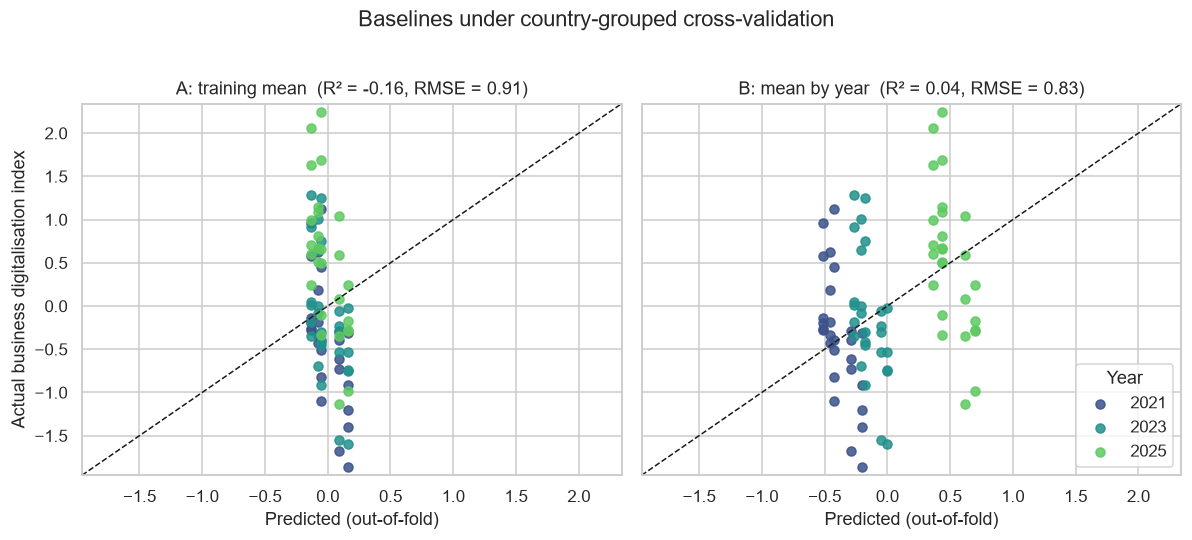

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
lims = (min(y.min(), oof_A.min(), oof_B.min()) - 0.1, max(y.max(), oof_A.max(), oof_B.max()) + 0.1)
palette = dict(zip(sorted(df["year"].unique()), sns.color_palette("viridis", df["year"].nunique())))

for ax, oof, pooled, title in [
    (axes[0], oof_A, pooled_A, "A: training mean"),
    (axes[1], oof_B, pooled_B, "B: mean by year"),
]:
    for yr, g in df.groupby("year"):
        ax.scatter(oof[g.index], y[g.index], s=35, alpha=0.85, color=palette[yr], label=str(yr))
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(f"{title}  (R² = {pooled['R2']:.2f}, RMSE = {pooled['RMSE']:.2f})")
    ax.set_xlabel("Predicted (out-of-fold)")
axes[0].set_ylabel("Actual business digitalisation index")
axes[1].legend(title="Year", loc="lower right")
fig.suptitle("Baselines under country-grouped cross-validation", y=1.02)
plt.tight_layout()
save_fig("09_baseline_predictions")
plt.show()

**How to read the chart.** A perfect model would put every point on the dashed diagonal. Baseline A predicts one value per fold (the training mean), so the points form a few vertical stripes. Baseline B predicts one value per year and fold, so the points group by colour: 2021 on the left, 2025 on the right. It separates the years but cannot tell countries apart (each stripe is tall). Our real models must spread the points horizontally *and* along the diagonal.

## 9. How to read these numbers

- **Always compare with the right baseline.** A model "beats the mean" easily on a trending target; the fair benchmark is baseline B.
- **R² near 0 or negative for baseline A is normal**, not a sign of a mistake.
- **MAE vs RMSE.** If RMSE is much larger than MAE, a few countries are predicted very badly (outliers). We will check which ones.
- **Noise.** With 27 countries, differences of a few hundredths in R² between models are within noise. Look at the per-fold spread before declaring a winner.
- **Same splits for every model.** `GroupKFold` is deterministic, so all future models will be evaluated on the identical folds, which makes comparisons fair.

### What I noticed
Predicting the training mean (baseline A) gives a negative R² (−0.16) and an RMSE of 0.91 under country-grouped cross-validation. This is expected for a model that uses no information. Fold-level R² is very unstable (down to −2.3) because each fold holds only 5–6 countries, so I rely on pooled out-of-fold metrics. Knowing only the year (baseline B) improves every metric (R² 0.04, RMSE 0.83; with leave-one-country-out R² 0.14, RMSE 0.79). In the chart, the points of B separate by colour (2021 on the left, 2025 on the right), but each group is still very spread out vertically: the year captures the common upward trend, not the differences between countries. A real model has to clearly beat baseline B, and with only 27 countries small gains should be read with caution.

## 10. Checklist before moving on

- [ ] I can explain why R² can be negative in cross-validation.
- [ ] I can explain the difference between MAE and RMSE.
- [ ] I checked that train and test countries never overlap.
- [ ] I know the pooled R² and RMSE of baseline B: **that is the bar to beat**.
- [ ] `outputs/tables/baseline_results.csv` and `09_baseline_predictions.png` exist.

**Next notebook (`04_models_linear.ipynb`)**: Ridge, Lasso and Elastic Net in a pipeline (imputation + scaling inside each fold), with hyperparameters chosen by nested cross-validation, compared with these baselines.